# Experiment No. 11 (Computer Laboratory – I BE AI&DS)

**Aim:** Data Aggregation  
**Problem Statement:** Analyzing Sales Performance by Region in a Retail Company  
**Dataset:** `"Retail_Sales_Data.csv"`  

**Tasks to Perform:**
1. Import the "Retail_Sales_Data.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Identify the relevant variables for aggregating sales data (Region, Sales_Amount, Product_Category).
4. Group the sales data by region and calculate the total sales amount for each region.
5. Create bar plots or pie charts to visualize the sales distribution by region.
6. Identify the top-performing regions based on the highest sales amount.
7. Group the sales data by region and product category to calculate the total sales amount for each combination.
8. Create stacked bar plots or grouped bar plots to compare the sales amounts across different regions and product categories.

In [1]:
# Cell 1 - Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

print("NumPy, Pandas, and Matplotlib imported successfully!")

NumPy, Pandas, and Matplotlib imported successfully!


In [2]:
# Cell 2 - Tasks 1, 2 & 3: Import, Explore Dataset & Identify Relevant Variables
# Task 1: Load dataset (with automatic sample generation if not present)
if not os.path.exists("Retail_Sales_Data.csv"):
    np.random.seed(42)
    n = 200
    dates = pd.date_range("2024-01-01", periods=90, freq="D")
    regions = ["North", "South", "East", "West", "Central"]
    categories = ["Electronics", "Clothing", "Home Appliances", "Footwear", "Groceries"]
    prices = {"Electronics": 1200, "Clothing": 450, "Home Appliances": 850, "Footwear": 350, "Groceries": 120}
    trans_ids = [f"TXN{1001 + i}" for i in range(n)]
    trans_dates = np.random.choice(dates, size=n)
    trans_reg = np.random.choice(regions, size=n, p=[0.28, 0.22, 0.18, 0.20, 0.12])
    trans_cat = np.random.choice(categories, size=n, p=[0.25, 0.25, 0.20, 0.15, 0.15])
    trans_qty = np.random.randint(1, 10, size=n)
    trans_sales = [trans_qty[i] * prices[trans_cat[i]] + int(np.random.normal(0, 25)) for i in range(n)]
    sample_df = pd.DataFrame({
        "Transaction_ID": trans_ids,
        "Date": [pd.to_datetime(d).strftime("%Y-%m-%d") for d in trans_dates],
        "Region": trans_reg,
        "Product_Category": trans_cat,
        "Quantity_Sold": trans_qty,
        "Sales_Amount": trans_sales
    })
    sample_df.to_csv("Retail_Sales_Data.csv", index=False)
    print("Created Retail_Sales_Data.csv successfully!")

df = pd.read_csv("Retail_Sales_Data.csv")

# Task 2: Explore dataset structure
print("Dataset Shape (Rows, Columns):", df.shape)
print("\nFirst 5 Records:")
display(df.head()) if "display" in globals() else print(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Value Count per Column:")
print(df.isnull().sum())

print("\nStatistical Summary of Numerical Features:")
display(df.describe()) if "display" in globals() else print(df.describe())

# Task 3: Identify relevant variables for aggregation
print("=" * 55)
print("       IDENTIFIED RELEVANT VARIABLES FOR AGGREGATION")
print("=" * 55)
print("1. Grouping Dimension 1: Region (Categorical - North, South, East, West, Central)")
print("2. Grouping Dimension 2: Product_Category (Categorical)")
print("3. Primary Numerical Metric: Sales_Amount (Total revenue in currency units)")
print("4. Secondary Numerical Metric: Quantity_Sold (Total items purchased)")
print("5. Temporal Index: Date (Transaction date)")
print("=" * 55)

Dataset Shape (Rows, Columns): (200, 6)

First 5 Records:
  Transaction_ID        Date Region Product_Category  Quantity_Sold  \
0        TXN1001  2024-02-21  South      Electronics              1   
1        TXN1002  2024-01-15  South         Clothing              1   
2        TXN1003  2024-03-12  South         Clothing              8   
3        TXN1004  2024-03-01  North  Home Appliances              2   
4        TXN1005  2024-01-21   East  Home Appliances              8   

   Sales_Amount  
0          1214  
1           445  
2          3609  
3          1685  
4          6802  

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction_ID    200 non-null    str  
 1   Date              200 non-null    str  
 2   Region            200 non-null    str  
 3   Product_Category  200 non-null    str  
 4   Quantity_Sold    

In [3]:
# Cell 3 - Tasks 4 & 6: Group by Region, Aggregate Sales & Identify Top Performers
# Task 4: Group sales data by region and calculate total sales amount and summary metrics
regional_summary = df.groupby("Region").agg(
    Total_Sales=("Sales_Amount", "sum"),
    Average_Sales=("Sales_Amount", "mean"),
    Total_Quantity=("Quantity_Sold", "sum"),
    Transaction_Count=("Transaction_ID", "count")
).round(2)

# Calculate percentage revenue share for each region
total_revenue_overall = regional_summary["Total_Sales"].sum()
regional_summary["Sales_Share_Pct"] = ((regional_summary["Total_Sales"] / total_revenue_overall) * 100).round(2)

# Task 6: Rank regions by highest sales amount
regional_summary = regional_summary.sort_values(by="Total_Sales", ascending=False)

print("=" * 68)
print("             REGIONAL SALES PERFORMANCE SUMMARY (RANKED)")
print("=" * 68)
display(regional_summary) if "display" in globals() else print(regional_summary)

top_region = regional_summary.index[0]
top_sales = regional_summary.loc[top_region, "Total_Sales"]
top_share = regional_summary.loc[top_region, "Sales_Share_Pct"]

lowest_region = regional_summary.index[-1]
lowest_sales = regional_summary.loc[lowest_region, "Total_Sales"]

print("-" * 68)
print(f"★ TOP PERFORMING REGION    : {top_region} with Total Sales of {top_sales:,.2f} ({top_share}% share)")
print(f"▼ LOWEST PERFORMING REGION : {lowest_region} with Total Sales of {lowest_sales:,.2f}")
print("-" * 68)

             REGIONAL SALES PERFORMANCE SUMMARY (RANKED)
         Total_Sales  Average_Sales  Total_Quantity  Transaction_Count  \
Region                                                                   
North         154974        2718.84             254                 57   
East          140912        3063.30             218                 46   
South         125215        3577.57             210                 35   
West          101104        2660.63             170                 38   
Central        79258        3302.42             125                 24   

         Sales_Share_Pct  
Region                    
North              25.77  
East               23.43  
South              20.82  
West               16.81  
Central            13.18  
--------------------------------------------------------------------
★ TOP PERFORMING REGION    : North with Total Sales of 154,974.00 (25.77% share)
▼ LOWEST PERFORMING REGION : Central with Total Sales of 79,258.00
------------------

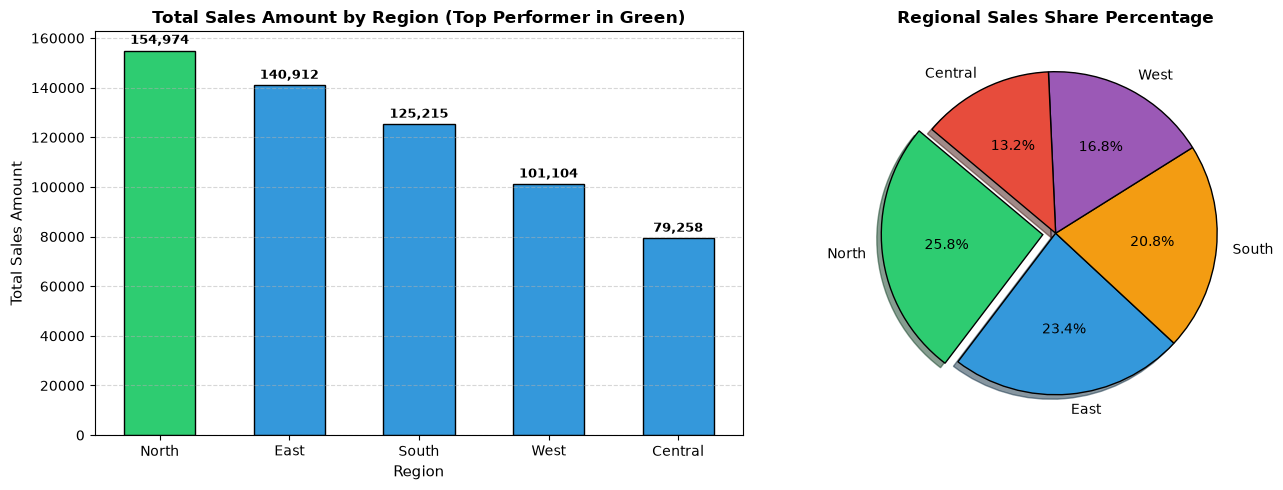

In [4]:
# Cell 4 - Task 5: Visualize Sales Distribution by Region (Bar Plot & Pie Chart)
plt.figure(figsize=(14, 5))

# Subplot 1: Bar Plot of Total Sales by Region
plt.subplot(1, 2, 1)
colors = ["#2ecc71" if reg == top_region else "#3498db" for reg in regional_summary.index]
bars = plt.bar(regional_summary.index, regional_summary["Total_Sales"], color=colors, edgecolor="black", width=0.55)
plt.title("Total Sales Amount by Region (Top Performer in Green)", fontsize=12, fontweight="bold")
plt.xlabel("Region", fontsize=11)
plt.ylabel("Total Sales Amount", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 1500, f"{height:,.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

# Subplot 2: Pie Chart of Regional Sales Contribution
plt.subplot(1, 2, 2)
explode = [0.08 if reg == top_region else 0 for reg in regional_summary.index]
palette = ["#2ecc71", "#3498db", "#f39c12", "#9b59b6", "#e74c3c"]
plt.pie(regional_summary["Total_Sales"], labels=regional_summary.index, autopct="%1.1f%%",
        startangle=140, explode=explode, colors=palette, shadow=True,
        wedgeprops={"edgecolor": "black", "linewidth": 1})
plt.title("Regional Sales Share Percentage", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

In [5]:
# Cell 5 - Task 7: Multi-Dimensional Grouping (Region & Product Category)
# Task 7: Group sales by Region and Product_Category to calculate total sales for each combination
region_cat_sales = df.groupby(["Region", "Product_Category"])["Sales_Amount"].sum().unstack(fill_value=0)

print("=" * 75)
print("       TOTAL SALES AMOUNT BY REGION AND PRODUCT CATEGORY (PIVOT TABLE)")
print("=" * 75)
display(region_cat_sales) if "display" in globals() else print(region_cat_sales)

# Pivot table with grand totals across rows and columns
pivot_with_totals = df.pivot_table(
    index="Region",
    columns="Product_Category",
    values="Sales_Amount",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Grand Total"
)
print("\nPivot Table with Row & Column Grand Totals:")
display(pivot_with_totals) if "display" in globals() else print(pivot_with_totals)

       TOTAL SALES AMOUNT BY REGION AND PRODUCT CATEGORY (PIVOT TABLE)
Product_Category  Clothing  Electronics  Footwear  Groceries  Home Appliances
Region                                                                       
Central              12441        37231      7370       2697            19519
East                 21536        61159     18889       2676            36652
North                13248        63468     10924       8694            58640
South                26536        67153      6037       6789            18700
West                 18934        52663      9796       4409            15302

Pivot Table with Row & Column Grand Totals:
Product_Category  Clothing  Electronics  Footwear  Groceries  Home Appliances  \
Region                                                                          
Central              12441        37231      7370       2697            19519   
East                 21536        61159     18889       2676            36652   
North         

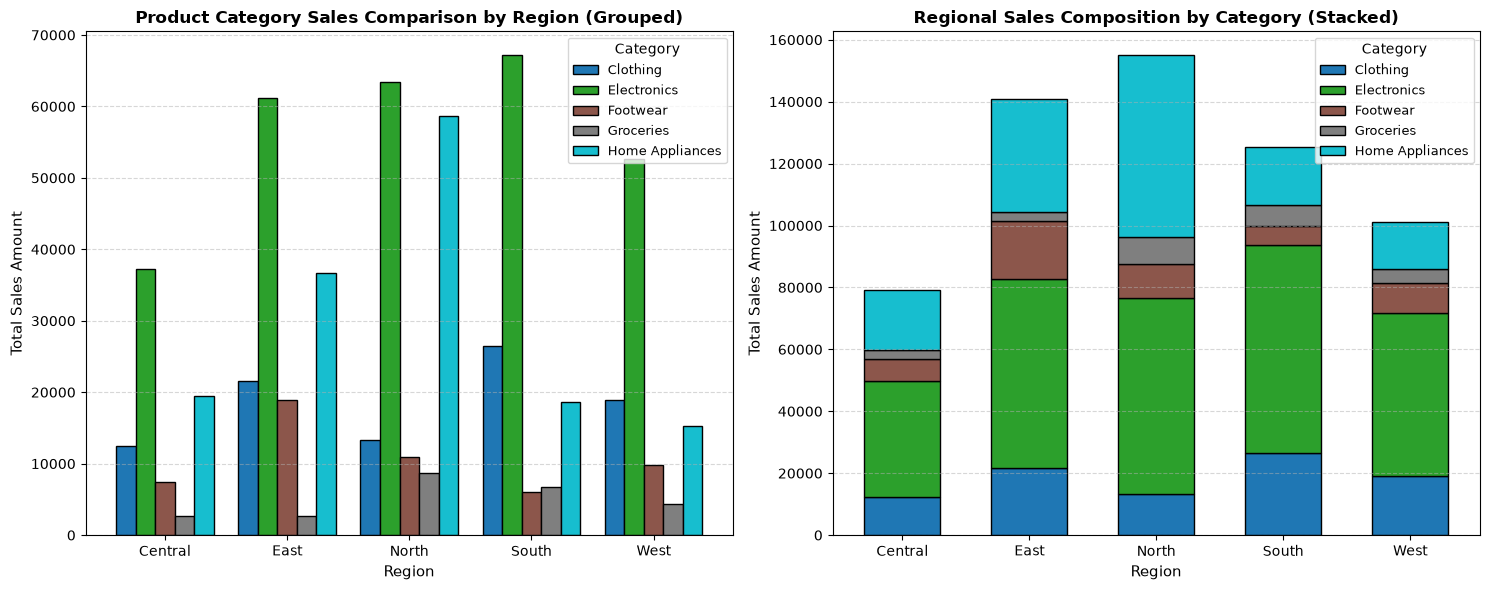

In [6]:
# Cell 6 - Task 8: Compare Sales Across Regions and Product Categories (Grouped & Stacked Bar Plots)
plt.figure(figsize=(15, 6))

# Subplot 1: Grouped Bar Plot (Categories side-by-side per region)
ax1 = plt.subplot(1, 2, 1)
region_cat_sales.plot(kind="bar", ax=ax1, width=0.8, edgecolor="black", colormap="tab10")
ax1.set_title("Product Category Sales Comparison by Region (Grouped)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Region", fontsize=11)
ax1.set_ylabel("Total Sales Amount", fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.5)
ax1.legend(title="Category", fontsize=9, loc="upper right")
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)

# Subplot 2: Stacked Bar Plot (Cumulative contribution per region)
ax2 = plt.subplot(1, 2, 2)
region_cat_sales.plot(kind="bar", stacked=True, ax=ax2, width=0.6, edgecolor="black", colormap="tab10")
ax2.set_title("Regional Sales Composition by Category (Stacked)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Region", fontsize=11)
ax2.set_ylabel("Total Sales Amount", fontsize=11)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.legend(title="Category", fontsize=9, loc="upper right")
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

In [7]:
# Cell 7 - Final Evaluation & Summary of Business Insights
print("=" * 68)
print("             EXECUTIVE BUSINESS INSIGHTS & AGGREGATION FINDINGS")
print("=" * 68)

# 1. Best Selling Category Overall
top_cat = df.groupby("Product_Category")["Sales_Amount"].sum().idxmax()
top_cat_sales = df.groupby("Product_Category")["Sales_Amount"].sum().max()
print(f"1. Highest Revenue Generating Category Overall : {top_cat} ({top_cat_sales:,.2f})")

# 2. Best Category per Region
print("\n2. Top Performing Product Category by Region:")
for region in region_cat_sales.index:
    best_cat = region_cat_sales.loc[region].idxmax()
    sales_val = region_cat_sales.loc[region, best_cat]
    print(f"   - Region {region:<8}: {best_cat} ({sales_val:,.2f})")

# 3. Overall Company KPI Summary
total_revenue = df["Sales_Amount"].sum()
avg_order_value = df["Sales_Amount"].mean()
total_units = df["Quantity_Sold"].sum()
total_transactions = len(df)

print("\n3. Overall Company KPI Summary:")
print(f"   - Total Revenue Generated : {total_revenue:,.2f}")
print(f"   - Total Units Sold        : {total_units:,}")
print(f"   - Total Transactions      : {total_transactions:,}")
print(f"   - Average Order Value     : {avg_order_value:,.2f}")
print("=" * 68)

             EXECUTIVE BUSINESS INSIGHTS & AGGREGATION FINDINGS
1. Highest Revenue Generating Category Overall : Electronics (281,674.00)

2. Top Performing Product Category by Region:
   - Region Central : Electronics (37,231.00)
   - Region East    : Electronics (61,159.00)
   - Region North   : Electronics (63,468.00)
   - Region South   : Electronics (67,153.00)
   - Region West    : Electronics (52,663.00)

3. Overall Company KPI Summary:
   - Total Revenue Generated : 601,463.00
   - Total Units Sold        : 977
   - Total Transactions      : 200
   - Average Order Value     : 3,007.32
